# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Y.Sandhya   
**Roll Number:** AP24110011857    
**Date:** 09/10/26

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [ ]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:*
The 70/30 split has higher entropy than the 90/10 split because its labels are more evenly distributed, making it harder to guess the correct label. The 90/10 split has lower entropy because one label dominates, making the prediction easier.

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [3]:
# Write your answer here
import math

# Entropy of parent
p1 = 8 / 14
p2 = 6 / 14

entropy_parent = -(p1 * math.log2(p1) + p2 * math.log2(p2))
print("Entropy of Parent:", round(entropy_parent, 4))

# Entropy of left child (6 Yes, 0 No)
entropy_left = 0
print("Entropy of Left Child:", entropy_left)

# Entropy of right child (2 Yes, 6 No)
p3 = 2 / 8
p4 = 6 / 8

entropy_right = -(p3 * math.log2(p3) + p4 * math.log2(p4))
print("Entropy of Right Child:", round(entropy_right, 4))

# Weighted entropy
weighted_entropy = (6 / 14) * entropy_left + (8 / 14) * entropy_right
print("Weighted Entropy:", round(weighted_entropy, 4))

# Information Gain
information_gain = entropy_parent - weighted_entropy
print("Information Gain:", round(information_gain, 4))

Entropy of Parent: 0.9852
Entropy of Left Child: 0
Entropy of Right Child: 0.8113
Weighted Entropy: 0.4636
Information Gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [4]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [10]:
import numpy as np
import pandas as pd

# Step 1: Define entropy function
def entropy(counts):
    probabilities = counts / counts.sum()
    probabilities = probabilities[probabilities > 0]
    return -np.sum(probabilities * np.log2(probabilities))


# Step 2: Define information gain function
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0

    for value, subset in df.groupby(attribute):
        weighted += (len(subset) / len(df)) * entropy(
            subset[target].value_counts()
        )

    return total - weighted


# Step 3: Calculate entropy and information gain
print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind):', round(info_gain(tennis, 'Wind'), 4))

Root entropy: 0.9403
Gain(Wind): 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [12]:
# Write your answer here
# Information gain for the three attributes
print("Gain(Outlook):", round(info_gain(tennis, 'Outlook'), 4))
print("Gain(Temperature):", round(info_gain(tennis, 'Temperature'), 4))
print("Gain(Humidity):", round(info_gain(tennis, 'Humidity'), 4))

# ID3 selects the attribute with the highest information gain
attributes = ['Outlook', 'Temperature', 'Humidity']
gains = {a: info_gain(tennis, a) for a in attributes}

root = max(gains, key=gains.get)
print("\nRoot attribute:", root)

# Filter the non-pure branch: Outlook = Sunny
sunny = tennis[tennis['Outlook'] == 'Sunny']

print("\nInformation gain within the Sunny branch:")
for attribute in ['Temperature', 'Humidity', 'Wind']:
    print(f"Gain({attribute}):", round(info_gain(sunny, attribute), 4))

Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518

Root attribute: Outlook

Information gain within the Sunny branch:
Gain(Temperature): 0.571
Gain(Humidity): 0.971
Gain(Wind): 0.02


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:*
A pure branch contains samples from only one class, so there is no uncertainty (entropy = 0). The model can directly predict that class without further splitting.

## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


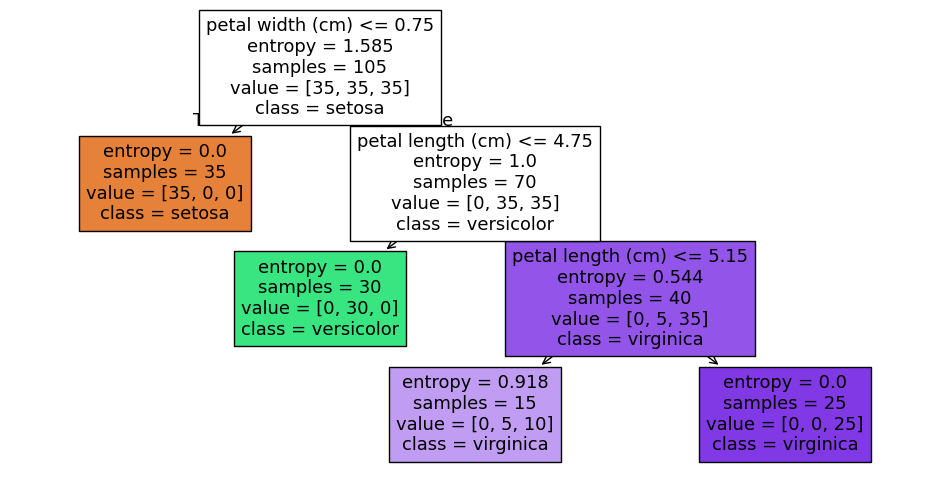

In [13]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


 max_depth  train_accuracy  test_accuracy
         1          0.6667         0.6667
         2          0.9524         0.9556
         3          0.9524         0.9778
         4          0.9714         0.9778
         5          0.9905         0.9778
         6          1.0000         0.9778
         7          1.0000         0.9778
         8          1.0000         0.9778
         9          1.0000         0.9778
        10          1.0000         0.9778
        11          1.0000         0.9778
        12          1.0000         0.9778
        13          1.0000         0.9778
        14          1.0000         0.9778
        15          1.0000         0.9778

Best depth: 3
Best test accuracy: 0.9778


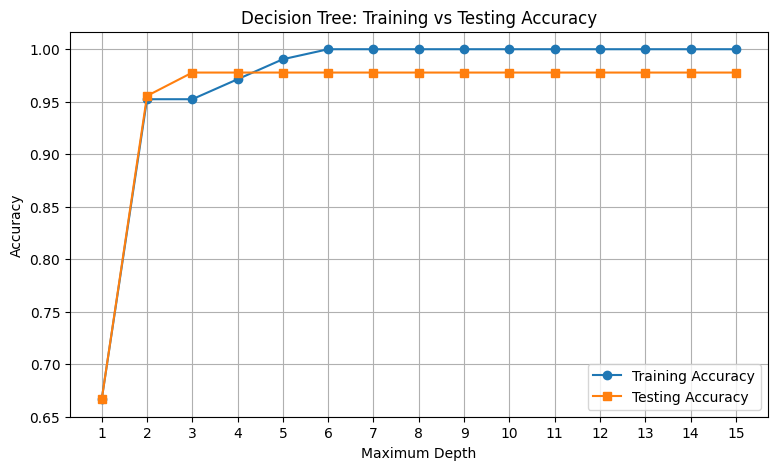

In [14]:
# Write your answer here
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Sweep max_depth from 1 to 15
results = []

for depth in range(1, 16):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    results.append({
        'max_depth': depth,
        'train_accuracy': train_acc,
        'test_accuracy': test_acc
    })

# Display results
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

# Find the best depth
best_row = results_df.loc[results_df['test_accuracy'].idxmax()]
print("\nBest depth:", int(best_row['max_depth']))
print("Best test accuracy:", round(best_row['test_accuracy'], 4))

# Plot training and testing accuracy
plt.figure(figsize=(9, 5))
plt.plot(results_df['max_depth'], results_df['train_accuracy'],
         marker='o', label='Training Accuracy')
plt.plot(results_df['max_depth'], results_df['test_accuracy'],
         marker='s', label='Testing Accuracy')

plt.xlabel('Maximum Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Training vs Testing Accuracy')
plt.xticks(range(1, 16))
plt.grid(True)
plt.legend()
plt.show()

**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:*
The Week 6 knob was the value of k in KNN, and the Week 7 knob was the regularization parameter or model complexity setting. These knobs control how complex or flexible a model is.

At one extreme, the model may be too simple and underfit the data. At the other extreme, it may be too complex and overfit the training data, resulting in poor test accuracy.

# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [15]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


In [16]:
# Write your answer here
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# Train the decision tree without scaling
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)

# Predict and calculate test accuracy
y_pred = tree.predict(Xd_test)
print("Test accuracy:", accuracy_score(yd_test, y_pred))

Test accuracy: 0.8814814814814815


**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*
The decision tree may be less accurate than KNN on the digits dataset because it makes decisions using individual feature thresholds. The importance map shows that the tree focuses on specific pixels, while KNN considers distances across all pixel features, which can help it recognize similar handwritten digits more accurately.

# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [17]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [18]:
# Write your answer here
from sklearn.tree import DecisionTreeClassifier, export_text

tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(X_text, labels)

rules = export_text(tree, feature_names=vocab)
print(rules)

|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking



**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:*
No, I would not necessarily expect the same split words because adding more sentences could change the patterns the tree learns. This shows that a decision tree trained on very little data may be unreliable and sensitive to the training examples. More diverse training data can help the tree learn more reliable patterns and improve its predictions.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
